Data loaded******
Data Calculated******


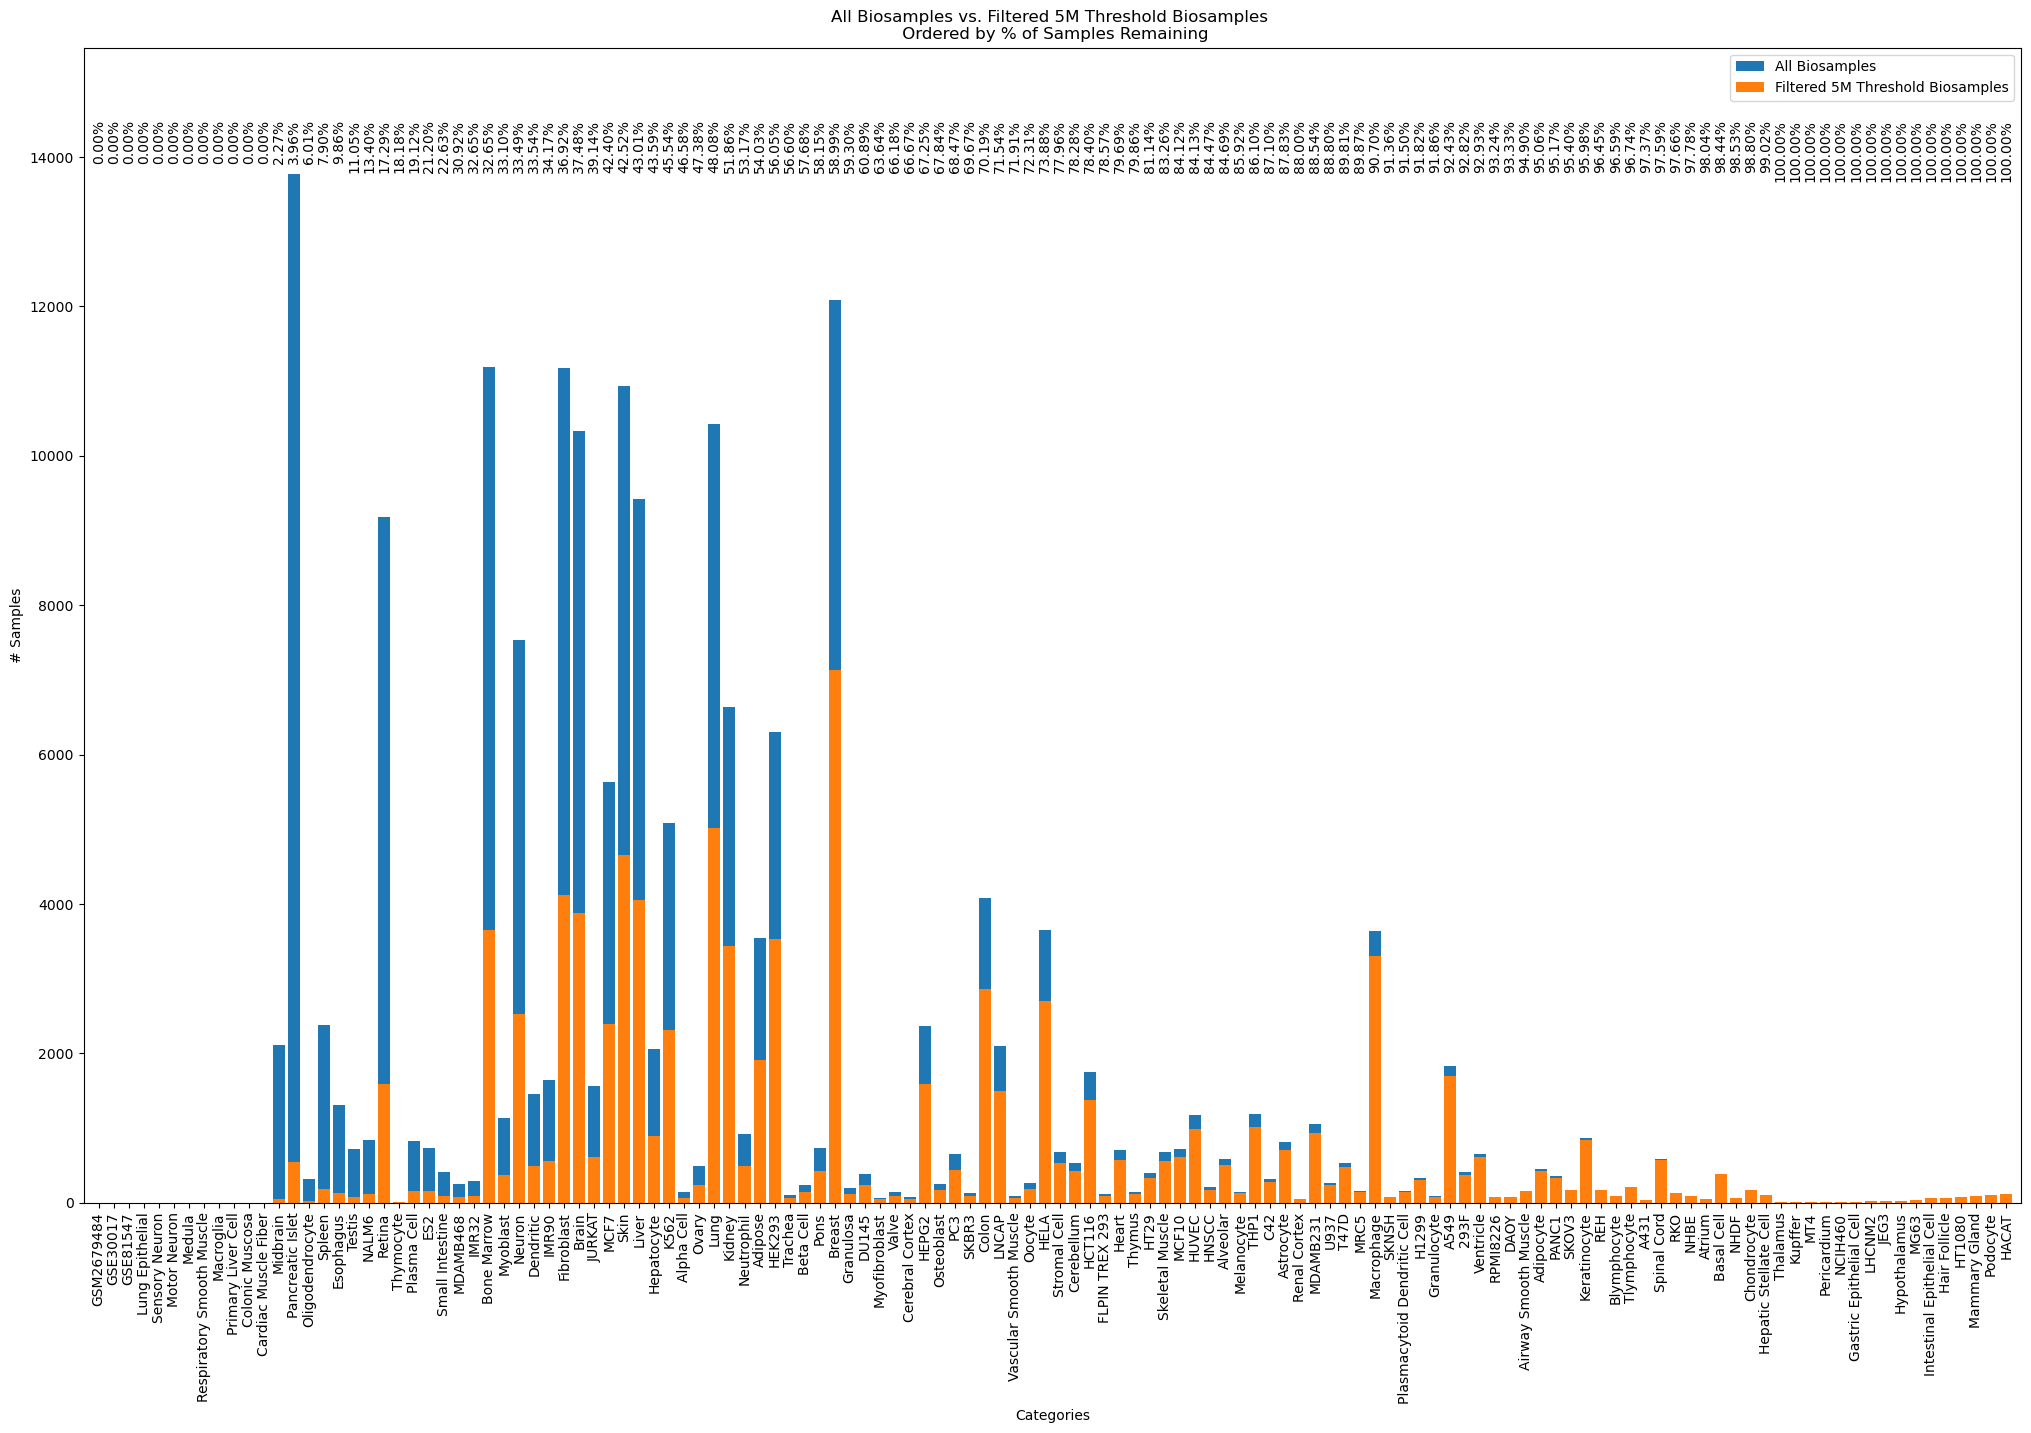

CPU times: user 2.11 s, sys: 437 ms, total: 2.55 s
Wall time: 2.46 s


In [71]:
%%time
import json
import matplotlib.pyplot as plt

# Load the data from the .json file
with open('/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/sbatch_files/results/category_uniqueSampleSizes_dict_LW20230121.json', 'r') as f:
    org_biosamples_dict = json.load(f)

# Print the value of the key 'key1'
#print(org_biosamples_dict['Heart'])

######
with open("filtered_category_uniqueSampleSizes_dict_LW20230123.json", "r") as f:
    filtered_sampleSize = json.load(f)

print("Data loaded******")
################################################################################################################

# Get the keys from both dictionaries
categories_list = list(org_biosamples_dict.keys())

# Get the values from both dictionaries
org_biosamples_values = [org_biosamples_dict[key] for key in categories_list]
filtered_biosamples_values = [filtered_sampleSize[key] for key in categories_list]

# Create a list of tuples containing the keys, values from dict1, and values from dict2
data = list(zip(categories_list, org_biosamples_values, filtered_biosamples_values))

# Sort the list of tuples based on the percentage of dict2/dict1 values in descending order
data = sorted(data, key=lambda x: (x[2]/(x[1] + 0.0001)), reverse=True)

print("Data Calculated******")
################################################################################################################

# Unpack the tuples into separate lists
keys, dict1_values, dict2_values = zip(*data)

# Create the bar plot
fig, ax = plt.subplots()

# Set the x axis to be in reverse order
ax.set_xlim(len(categories_list) + 1, 0)

# Create the bars for dict2 values
bars = ax.bar(range(1, len(categories_list) + 1), dict1_values, label='All Biosamples')
ax.bar(range(1, len(categories_list) + 1), dict2_values, label='Filtered 5M Threshold Biosamples')

# Create the bars for dict1 values with transparency
#ax.bar(range(1, len(categories_list) + 1), dict1_values, label='Filtered 5M Threshold Biosamples')

# # Create the bars for dict2 values
# bars = ax.bar(range(1, len(categories_list) + 1), dict2_values, label='All Biosamples')

# # Create the stacked bars
# bars = ax.bar(range(1, len(categories_list) + 1), dict2_values, bottom=dict1_values, label='All Biosamples')
# ax.bar(range(1, len(categories_list) + 1), dict1_values, label='Filtered 5M Threshold Biosamples')


# Get the current y-axis limits
ymin, ymax = plt.ylim()

# Extend the y-axis by 10 units above the maximum value
plt.ylim(ymin, ymax+1000)

# Add the difference percentage labels on top of each bar
for i, bar in enumerate(bars):
    if dict1_values[i] == 0:
        diff_percent = 0.0
    else:
        diff_percent = (dict2_values[i] / (dict1_values[i] + 0.0001)) * 100
        
    ax.text(bar.get_x() + bar.get_width() / 2, 14500 , '{:.2f}%'.format(diff_percent), ha='center', va='top', rotation = 90)
    
# Set x-tick labels
ax.set_xticks(range(1, len(keys) + 1))
ax.set_xticklabels(keys, rotation = 90)

# Add labels and legend
plt.xlabel('Categories')
fig = plt.gcf()
fig.set_size_inches(25, 15)
plt.ylabel('# Samples')
plt.title('All Biosamples vs. Filtered 5M Threshold Biosamples \n Ordered by % of Samples Remaining')
plt.legend()

# Show the plot
plt.show()


In [54]:
org_biosamples_dict['Breast']

12090

In [55]:
filtered_sampleSize['Breast']

7132

# Example Code

In [32]:
import matplotlib.pyplot as plt

# Sample dictionaries
dict1 = {'A': 10, 'B': 20, 'C': 30, 'D':0}
dict2 = {'A': 8, 'B': 15, 'C': 25, 'D':35}

# Get the keys from both dictionaries
keys = list(dict1.keys())

# Get the values from both dictionaries
dict1_values = [dict1[key] for key in keys]
dict2_values = [dict2[key] for key in keys]

# Create a list of tuples containing the keys, values from dict1, and values from dict2
data = list(zip(keys, dict1_values, dict2_values))

# Sort the list of tuples based on the difference percentage between dict1 and dict2 values
data = sorted(data, key=lambda x: ((x[1]-x[2])/x[1])*100, reverse=True)

# Unpack the tuples into separate lists
keys, dict1_values, dict2_values = zip(*data)

# Create the stacked bar plot
fig, ax = plt.subplots()
ax.bar(keys, dict1_values, label='dict1')
ax.bar(keys, dict2_values, bottom=dict1_values, label='dict2')

# Add labels and legend
plt.xlabel('Keys')
plt.xticks(rotation=90)
plt.ylabel('Values')
plt.legend()

# Show the plot
plt.show()


ZeroDivisionError: division by zero

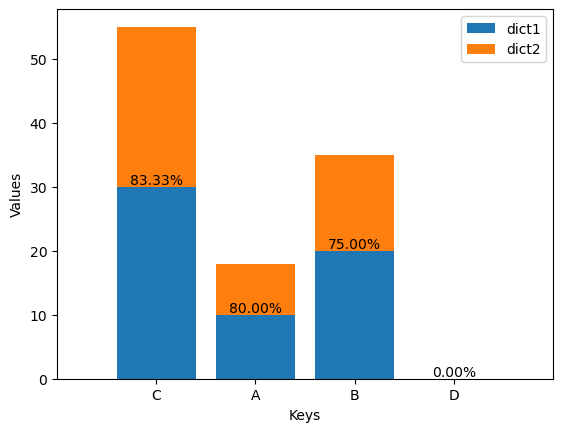

In [56]:
import matplotlib.pyplot as plt

# Sample dictionaries
dict1 = {'A': 10, 'B': 20, 'C': 30, 'D':0}
dict2 = {'A': 8, 'B': 15, 'C': 25, 'D':0}

# Get the keys from both dictionaries
keys = list(dict1.keys())

# Get the values from both dictionaries
dict1_values = [dict1[key] for key in keys]
dict2_values = [dict2[key] for key in keys]

# Create a list of tuples containing the keys, values from dict1, and values from dict2
data = list(zip(keys, dict1_values, dict2_values))

# Sort the list of tuples based on the percentage of dict2/dict1 values in descending order
data = sorted(data, key=lambda x: (x[2]/(x[1] + 0.0001)), reverse=False)

# Unpack the tuples into separate lists
keys, dict1_values, dict2_values = zip(*data)

# Create the stacked bar plot
fig, ax = plt.subplots()

# Set the x axis to be in reverse order
ax.set_xlim(len(keys) + 1, 0)

# Create the stacked bars
bars = ax.bar(range(1, len(keys) + 1), dict1_values, label='dict1')
ax.bar(range(1, len(keys) + 1), dict2_values, bottom=dict1_values, label='dict2')

# Add the difference percentage labels on top of each bar
for i, bar in enumerate(bars):
    diff_percent = (dict2_values[i] / (dict1_values[i] + 0.0001)) * 100
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), '{:.2f}%'.format(diff_percent), ha='center', va='bottom')
    
# Set x-tick labels
ax.set_xticks(range(1, len(keys) + 1))
ax.set_xticklabels(keys)

# Add labels and legend
plt.xlabel('Keys')
plt.ylabel('Values')
plt.legend()

# Show the plot
plt.show()


